# Krok 10. Trzy baseline'y z parametrów EDA (baseline_0, baseline_1, baseline_2)
**Po co ten notebook.** Kroki 01–09 policzyły parametry (mnożniki, okna, typy popytu, promocje, flagi czyszczenia), ale nikt jeszcze nie zamienił ich w prognozę. Tu składamy z nich trzy punkty odniesienia i **po raz pierwszy** oceniamy je na roku testowym 2025. To jedyny notebook, który wolno otworzyć na danych po 2024; reszta EDA ich nie widzi.

**Trzy warianty.**
| wariant | jak liczy tydzień N | z czego korzysta |
|---|---|---|
| `baseline_0` | średnia tego samego tygodnia ISO z lat 2023–2024, osobno dla każdego towaru (SKU) | nic z EDA (poprzeczka) |
| `baseline_1` | jak baseline_0, ale tygodnie wielkanocne bierze z tego samego położenia względem Wielkanocy (k), a zwykłe tygodnie bez lat, w których ten numer był wielkanocny | krok 5 (zakres k) |
| `baseline_2` | **poziom bazowy towaru × mnożniki asortymentu** (dzień tygodnia, tydzień roku, Wielkanoc, wydarzenia) | kroki 1, 4, 5, 6, 8, 9 (oraz 7 przy liczeniu poziomu) |

**Skąd co pochodzi (baseline_2).**
- **Mnożnik dnia tygodnia:** `wynik_04` (profil własny albo profil sklepu).
- **Mnożnik tygodnia roku:** `wynik_05_mnoznik_tygodnia_roku`, ale tylko dla asortymentów, w których wzór roczny dał zysk (`wynik_01`, próg `PROG_ZYSKU_SEZON`); w pozostałych mnożnik = 1.
- **Wielkanoc:** `wynik_05_wielkanoc_tygodnie` (mnożnik k razy poziom tygodni odniesienia).
- **Wydarzenia:** `wynik_06_wydarzenia` (tylko potwierdzone efekty, w dniach przesunięcia) i lista wydarzeń z `wynik_06_definicje.json`.
- **Poziom bazowy towaru:** reguła z `wynik_08_reguly` dla typu popytu towaru (`wynik_08_typy_popytu`): średnia, mediana lub Croston. Do poziomu **nie wchodzą dni promocji** (`CzyPromocja`) i jednorazowe nadwyżki (`wynik_09_jednorazowe`); towary wycofane (`wynik_09_flagi_sku`) dostają prognozę 0.

**Jak uniknąć wycieku z przyszłości.** Wszystkie prognozy powstają z jednego punktu startu `ORIGIN` (poniedziałek 2024-12-30). Poziom towaru liczymy tylko z tygodni przed `ORIGIN`. Mnożniki pochodzą z EDA na latach 2023–2024; jedyne zastrzeżenie: EDA widziało też 30–31.12.2024, czyli 2 dni z pierwszego tygodnia testowego z ponad 700 dni, więc wpływ jest pomijalny. Kalendarz (święta, niedziele handlowe) znamy z góry, więc wolno go użyć także dla 2025.

**Różnice względem Części IV starego notebooka.** Tu asortyment 319 (towary przecenione) jest wyłączony, poziom nie zawiera dni promocji, a metoda zależy od typu popytu. Wyniki baseline_0 i baseline_1 mogą się więc nieco różnić od Części IV.

In [1]:
# Ustawienia wspólne: moduł eda_wspolne.py leży obok tego notebooka
import os, sys
sys.path.insert(0, os.getcwd())
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_wspolne as ew

ew.wejdz_do_korzenia()      # przechodzi do katalogu głównego projektu (tam, gdzie jest plik z danymi)
ew.styl()
print("Katalog projektu:", os.getcwd(), "| EDA używa danych do", ew.KONIEC_EDA.date(), "(rok testowy", ew.ROK_TEST, "pomijamy)")

Katalog projektu: /Users/mixer/python/analiza_sprzedazy_w_sklepie | EDA używa danych do 2024-12-31 (rok testowy 2025 pomijamy)


## 1. Dane: tydzień × towar i kalendarz do końca danych
#### Objaśnienie
**Po co.** Budujemy tabelę sprzedaży tygodniowej każdego towaru (wiersze: towary, kolumny: pełne tygodnie od poniedziałku) i kalendarz dzienny do końca danych. Funkcje z `eda_wspolne` mają parametr `do`, którym tylko ten notebook przesuwa koniec danych poza 2024.
**Parametry (do edycji).**
- `ORIGIN`: poniedziałek, od którego prognozujemy; historia to wszystko przed nim.
- `OKNO_POZIOMU_TYG`: z ilu ostatnich tygodni liczymy poziom towaru. Dla prognozy na cały rok sensowne jest długie okno (52), bo krótkie okno z kroku 3 (4–8 tygodni) było dobrane do prognozy na 4 tygodnie. Wrażliwość sprawdzamy niżej.
- `PROG_ZYSKU_SEZON`: mnożnik tygodnia roku stosujemy tylko tam, gdzie krok 1 pokazał zysk wzoru rocznego co najmniej tyle procent (`None` = zawsze).
**Jak czytać wynik.** Powinno być około 57 tygodni testowych (do końca danych), towary z historią i bez niej. Ostatni tydzień danych uznajemy za pełny, jeśli mamy sobotę, bo sklep w niedzielę nie handluje (poza niedzielami handlowymi).

In [2]:
import json
from dateutil.easter import easter

ORIGIN = pd.Timestamp("2024-12-30")      # poniedziałek: prognozy powstają wyłącznie z danych sprzed tej daty
OKNO_POZIOMU_TYG = 52                    # ile ostatnich tygodni przed ORIGIN daje poziom bazowy towaru
PROG_ZYSKU_SEZON = 10.0                  # mnożnik tygodnia roku tylko dla asortymentów z zyskiem >= tyle % (krok 1); None = zawsze
POKRYCIE_BEZ_PROMO = 0.3                 # poziom bez dni promocji liczymy, gdy zostaje co najmniej tyle "normalnych" dni; inaczej bierzemy wszystkie

KONIEC_DANYCH = pd.Timestamp(pd.read_parquet(ew.PLIK_REL, columns=["Data"])["Data"].max())
dod = [c for c in ["CzyPromocja", "KategoriaABCD"] if ew.ma_kolumne(c)]
fa = ew.wczytaj_sprzedaz(dodatkowe=dod, do=KONIEC_DANYCH)
kal = ew.kalendarz(do=KONIEC_DANYCH)
dni = kal.index

# pełne tygodnie: poniedziałek >= pierwszy dzień danych; ostatni tydzień liczymy, jeśli mamy sobotę (niedziela zwykle zamknięta)
pn0 = dni.min() + pd.Timedelta(days=(7 - dni.min().dayofweek) % 7)
pn_ost = dni.max() - pd.Timedelta(days=dni.max().dayofweek)
if dni.max().dayofweek < 5:
    pn_ost -= pd.Timedelta(days=7)
tygodnie = pd.date_range(pn0, pn_ost, freq="7D")
W = len(tygodnie)
fa = fa[fa["Data"] <= pn_ost + pd.Timedelta(days=6)]
fa = fa.assign(Tyg=fa["Data"] - pd.to_timedelta(fa["Data"].dt.dayofweek, unit="D"))

sku_tyg = (fa.groupby(["SKU", "Tyg"], observed=True)[ew.MIARA].sum().unstack("Tyg").reindex(columns=tygodnie).fillna(0))
A = sku_tyg.values.astype(float)
SKU = sku_tyg.index.values
mapa = (fa.groupby(["SKU", "AsId"], observed=True).size().rename("n").reset_index()
          .sort_values("n", ascending=False).drop_duplicates("SKU").set_index("SKU")["AsId"])
as_sku = mapa.reindex(SKU).astype("Int64").astype(str).where(mapa.reindex(SKU).notna(), None).values        # asortyment towaru (tekst)
klasa_sku = (fa.groupby("SKU", observed=True)["KategoriaABCD"].first().reindex(SKU).values if "KategoriaABCD" in fa else np.full(len(SKU), None))

# dni promocji z historii (do wyłączenia z poziomu): towar, tydzień, dzień, sztuki
if "CzyPromocja" in fa:
    pr = fa[(fa["CzyPromocja"].fillna(0).astype(int) == 1) & (fa["Data"] < ORIGIN)]
    pr = pr.groupby(["SKU", "Data"], observed=True)[ew.MIARA].sum().reset_index()
    pr_i = pd.Index(SKU).get_indexer(pr["SKU"])
    pr_t = tygodnie.get_indexer(pr["Data"] - pd.to_timedelta(pr["Data"].dt.dayofweek, unit="D"))
    pr_d = dni.get_indexer(pr["Data"])
    pr_q = pr[ew.MIARA].values
    ok = (pr_i >= 0) & (pr_t >= 0) & (pr_d >= 0)
    pr_i, pr_t, pr_d, pr_q = pr_i[ok], pr_t[ok], pr_d[ok], pr_q[ok]
else:
    pr_i = pr_t = pr_d = np.array([], int); pr_q = np.array([])
del fa

idx_hist = np.where(tygodnie < ORIGIN)[0]
idx_test = np.where(tygodnie >= ORIGIN)[0]
ma_hist = (A[:, idx_hist] > 0).any(axis=1)
print(f"Towarów: {len(SKU):,} | tygodni: {W} ({tygodnie[0].date()} … {tygodnie[-1].date()})".replace(",", " "))
print(f"Historia przed {ORIGIN.date()}: {len(idx_hist)} tygodni | test: {len(idx_test)} tygodni | towary z historią: {int(ma_hist.sum())}")
print(f"Wiersze promocji w historii: {len(pr_q)}" + ("" if "CzyPromocja" in dod else " (brak kolumny CzyPromocja: poziom bez wyłączania promocji)"))

Towarów: 11 594 | tygodni: 161 (2023-01-02 … 2026-01-26)
Historia przed 2024-12-30: 104 tygodni | test: 57 tygodni | towary z historią: 9942
Wiersze promocji w historii: 49448


## 2. Wczytanie wyników EDA
#### Objaśnienie
**Po co.** Zbieramy w jednym miejscu parametry z kroków 1–9. Każdy plik ma jasny cel; jeśli któregoś brakuje, notebook zatrzyma się z komunikatem, który krok uruchomić.
**Co robi kod.**
- `P_dow` (asortymenty × dni): mnożnik dnia tygodnia; asortyment bez własnego wiersza dostaje profil sklepu (`SKLEP`).
- `P_woy` (asortymenty × tygodnie roku): mnożnik tygodnia roku, wyłączony (=1) tam, gdzie krok 1 nie potwierdził sensu wzoru rocznego.
- `K_wlk`: mnożniki tygodni wielkanocnych k; `kk` to zakres k z pliku.
- `typ`, `regula`, flagi: typ popytu każdego towaru i reguła liczenia poziomu.
**Jak czytać wynik.** Liczba asortymentów z włączonym wzorem rocznym mówi, w jakiej części sklepu mnożnik tygodnia roku w ogóle działa.

In [3]:
str_as = {"dtype": {"AsId": str}}
m4 = ew.wczytaj_wynik("wynik_04_mnoznik_dnia_tygodnia.csv", **str_as).set_index("AsId")
m5 = ew.wczytaj_wynik("wynik_05_mnoznik_tygodnia_roku.csv", **str_as)
m5k = ew.wczytaj_wynik("wynik_05_wielkanoc_tygodnie.csv", **str_as)
m6 = ew.wczytaj_wynik("wynik_06_wydarzenia.csv", **str_as)
m1 = ew.wczytaj_wynik("wynik_01_podobienstwo_lat.csv", **str_as).set_index("AsId")
typy = ew.wczytaj_wynik("wynik_08_typy_popytu.csv").set_index("SKU")["typ"]
reguly = ew.wczytaj_wynik("wynik_08_reguly.csv").set_index("typ")["regula"].to_dict()
flagi = ew.wczytaj_wynik("wynik_09_flagi_sku.csv").set_index("SKU")
jedn = ew.wczytaj_wynik("wynik_09_jednorazowe.csv", parse_dates=["Data"])
defs = json.load(open(os.path.join(ew.KATALOG_WYNIKOW, "wynik_06_definicje.json")))
STALE = {k: tuple(v) for k, v in defs["stale"].items()}
RUCHOME = defs["ruchome"]

AS = sorted({a for a in as_sku if a is not None}, key=lambda x: int(x))
col_as = np.array([AS.index(a) if a is not None else -1 for a in as_sku])      # kolumna asortymentu każdego towaru (-1 = brak)
nA = len(AS)

SKL = "SKLEP"
dzien_kol = ["Pn", "Wt", "Śr", "Cz", "Pt", "So"]
P_dow = np.ones((nA, 7))
for i, a in enumerate(AS):
    w = m4.loc[a, dzien_kol] if a in m4.index else m4.loc[SKL, dzien_kol]
    P_dow[i, :6] = w.values.astype(float)
P_dow[:, 6] = P_dow[:, 5]                       # niedziela handlowa: kształt jak sobota (korektę daje wydarzenie "Niedziela handlowa")

zysk = m1["zysk_%"].reindex(AS)
wzor_wlaczony = np.ones(nA, bool) if PROG_ZYSKU_SEZON is None else (zysk.values >= PROG_ZYSKU_SEZON)
P_woy = np.ones((nA, 54))
pw = m5.pivot(index="AsId", columns="TydzienISO", values="mnoznik_wygladzony")
for i, a in enumerate(AS):
    if wzor_wlaczony[i] and a in pw.index:
        v = pw.loc[a].reindex(range(1, 54)).values.astype(float)
        v[52] = v[51] if np.isnan(v[52]) else v[52]            # tydzień 53 = tydzień 52
        P_woy[i, 1:54] = np.where(np.isnan(v), 1.0, v)

kk = sorted(m5k["k"].unique())
K_wlk = np.ones((nA, len(kk)))
pk = m5k.pivot(index="AsId", columns="k", values="mnoznik")
for i, a in enumerate(AS):
    if a in pk.index:
        K_wlk[i] = np.where(np.isnan(pk.loc[a].reindex(kk).values), 1.0, pk.loc[a].reindex(kk).values)

def popraw(x, nazwa):
    # mnożnik nieskończony lub NaN zastępujemy 1 (brak informacji), a skrajne wartości ucinamy do [0, 10]
    zle = ~np.isfinite(x)
    if zle.any():
        print(f"Uwaga: {int(zle.sum())} nieokreślonych mnożników w {nazwa} zastąpiono przez 1,0")
    return np.clip(np.where(zle, 1.0, x), 0.0, 10.0)
P_dow = popraw(P_dow, "dniu tygodnia"); P_woy = popraw(P_woy, "tygodniu roku"); K_wlk = popraw(K_wlk, "tygodniach wielkanocnych")
print(f"Asortymentów: {nA} | z własnym profilem dnia: {int(sum(a in m4.index and m4.loc[a, 'zrodlo'] == 'wlasny' for a in AS))} | "
      f"z włączonym wzorem rocznego (zysk >= {PROG_ZYSKU_SEZON}%): {int(wzor_wlaczony.sum())}")
print("Zakres tygodni wielkanocnych k:", kk, "| reguły poziomu wg typu:", reguly)

Asortymentów: 238 | z własnym profilem dnia: 111 | z włączonym wzorem rocznego (zysk >= 10.0%): 42
Zakres tygodni wielkanocnych k: [-2, -1, 0, 1] | reguły poziomu wg typu: {'nieregularny': 'srednia_13', 'regularny': 'croston_sba', 'sporadyczny': 'srednia_13', 'zmienny': 'mediana', 'za_malo_danych': 'srednia_z_dostepnych_tygodni'}


## 3. baseline_0 i baseline_1
#### Objaśnienie
**Po co.** To dwa najprostsze punkty odniesienia, oba bez parametrów z EDA poza zakresem tygodni wielkanocnych.
**Co robi kod.**
- `baseline_0`: prognoza tygodnia N to średnia z tego samego numeru tygodnia ISO w latach 2023–2024 (tylko od tygodnia pierwszej sprzedaży towaru, bo wcześniejsze zera to brak towaru w ofercie).
- `baseline_1`: tydzień wielkanocny (k od najmniejszego do największego z pliku) dostaje średnią z tygodni o tym samym k z lat poprzednich. Zwykły tydzień pomija lata, w których ten numer był tygodniem wielkanocnym; gdy nic nie zostanie, bierze sąsiednie numery tygodni.
**Jak czytać wynik.** Lista tygodni testowych w oknie wielkanocnym powinna zawierać tygodnie Wielkanocy 2025 (20.04.2025). Wiersz „różni się od baseline_0" pokazuje, ile tygodni baseline_1 faktycznie zmienia.

In [4]:
wlk = {y: pd.Timestamp(easter(y)) for y in range(dni.year.min(), dni.year.max() + 1)}
pn_wlk = {y: e - pd.Timedelta(days=e.dayofweek) for y, e in wlk.items()}                  # poniedziałek tygodnia z Wielkanocą
nr_tyg = np.asarray(tygodnie.isocalendar().week)
rok_tyg = np.asarray(tygodnie.year)
k_wlk = np.array([(t - pn_wlk[y]).days // 7 for t, y in zip(tygodnie, rok_tyg)])
w_oknie = (k_wlk >= min(kk)) & (k_wlk <= max(kk))

pierwszy = np.where((A > 0).any(axis=1), (A > 0).argmax(axis=1), W)
aktywny = np.arange(W)[None, :] >= pierwszy[:, None]                                       # towary x tygodnie od 1. sprzedaży

def srednia_z_tygodni(tyg):
    if len(tyg) == 0:
        return np.full(A.shape[0], np.nan)
    ak = aktywny[:, tyg]
    n = ak.sum(axis=1)
    return np.where(n > 0, (A[:, tyg] * ak).sum(axis=1) / np.maximum(n, 1), np.nan)

F0 = np.full((len(SKU), len(idx_test)), np.nan)
F1 = F0.copy()
for j, tw in enumerate(idx_test):
    F0[:, j] = srednia_z_tygodni(idx_hist[nr_tyg[idx_hist] == nr_tyg[tw]])
    if w_oknie[tw]:
        F1[:, j] = srednia_z_tygodni(idx_hist[k_wlk[idx_hist] == k_wlk[tw]])
    else:
        for delta in (0, 1, 2):
            cele = {(nr_tyg[tw] - 1 - delta) % 52 + 1, (nr_tyg[tw] - 1 + delta) % 52 + 1}
            tyg = idx_hist[np.isin(nr_tyg[idx_hist], list(cele)) & ~w_oknie[idx_hist]]
            if len(tyg):
                F1[:, j] = srednia_z_tygodni(tyg)
                break
    brak = np.isnan(F1[:, j])
    F1[brak, j] = F0[brak, j]

print("Tygodnie testowe w oknie wielkanocnym:", [str(t.date()) for t in tygodnie[idx_test][w_oknie[idx_test]]])
print("Towary bez żadnej historii (brak prognozy):", int(np.isnan(F0).all(axis=1).sum()), "z", len(SKU))
print("baseline_1 różni się od baseline_0 w tygodniach:", int((np.abs(np.nan_to_num(F1) - np.nan_to_num(F0)).max(axis=0) > 1e-9).sum()), "z", len(idx_test))

Tygodnie testowe w oknie wielkanocnym: ['2025-03-31', '2025-04-07', '2025-04-14', '2025-04-21']
Towary bez żadnej historii (brak prognozy): 1652 z 11594
baseline_1 różni się od baseline_0 w tygodniach: 7 z 57


## 4. Mnożnik każdego dnia (dla baseline_2)
#### Objaśnienie
**Po co.** Dla każdego asortymentu i każdego dnia (także w 2025, bo kalendarz znamy z góry) składamy jeden mnożnik: o ile ten dzień sprzedaje więcej lub mniej niż przeciętny dzień. Suma mnożników z tygodnia mówi, ile „typowych dni" ma ten tydzień.
**Jak powstaje mnożnik dnia.**
1. **dzień tygodnia** (krok 4) × **tydzień roku** (krok 5, wygładzony; wyłączony tam, gdzie wzór roczny nie ma sensu);
2. w tygodniach wielkanocnych tydzień roku zastępuje **mnożnik k** (krok 5) razy poziom tygodni odniesienia (3–6 tygodni od Wielkanocy);
3. **wydarzenia** (krok 6, tylko potwierdzone): mnożnik dnia = data wydarzenia + przesunięcie. Gdy w jednym dniu nakłada się kilka wydarzeń, bierzemy to o największym efekcie, żeby nie liczyć dwa razy;
4. **niedziela handlowa**: kształt jak sobota razy mnożnik wydarzenia „Niedziela handlowa"; asortyment bez własnego potwierdzenia dostaje mnożnik sklepu;
5. **dzień zamknięty** = 0.
**Dwa tryby Wielkanocy.** `tydzien` (domyślny, krok 5) liczy Wielkanoc jako mnożnik tygodnia k. `dzien` używa zamiast tego mnożników dnia z kroku 6 (wydarzenie „Wielkanoc"). Oba sprawdzamy niżej.
**Jak czytać wynik.** Mediana sumy mnożników w zwykłym tygodniu powinna być bliska 6 (sześć dni otwartych po około 1); tygodnie z zamkniętymi dniami świątecznymi mają mniej.

In [5]:
idx_dnia = {d: i for i, d in enumerate(dni)}
dow = kal["DzienTyg"].values
otw = ~kal["Zamkniety"].values
nr_d = np.minimum(np.asarray(dni.isocalendar().week), 53)
LATA_WSZYSTKIE = tuple(range(dni.year.min(), dni.year.max() + 1))
terminy = ew.terminy_wydarzen(kal, LATA_WSZYSTKIE, STALE, RUCHOME)
m6s = m6[m6["AsId"] != SKL]
nd_dni = (kal["NdHandlowa"] & ~kal["Zamkniety"] & (kal["DzienTyg"] == 6)).values
nd_sklep = m6[(m6["AsId"] == SKL) & (m6["wydarzenie"] == "Niedziela handlowa") & (m6["offset"] == 0)]["mnoznik"]
nd_domyslny = float(nd_sklep.iloc[0]) if len(nd_sklep) else float(m6s[(m6s["wydarzenie"] == "Niedziela handlowa") & (m6s["offset"] == 0)]["mnoznik"].replace([np.inf, -np.inf], np.nan).median())
print("Mnożnik niedzieli handlowej względem soboty dla asortymentów bez własnego potwierdzenia:", round(nd_domyslny, 2))

def buduj_m_dzien(tryb_wlk="tydzien", uzyj=("dow", "woy", "wlk", "zdarz")):
    # uzyj = które składniki mnożnika włączamy (do testu, ile daje każdy z nich); pełny baseline_2 używa wszystkich
    # (1) dzień tygodnia x tydzień roku
    woy = P_woy[:, nr_d].T.copy() if "woy" in uzyj else np.ones((len(dni), nA))     # dni x asortymenty
    m_dow = P_dow[:, dow].T if "dow" in uzyj else np.ones((len(dni), nA))
    # (2) tygodnie wielkanocne: mnożnik k x poziom tygodni odniesienia
    if tryb_wlk == "tydzien" and "wlk" in uzyj:
        for y, pn in pn_wlk.items():
            ref = []
            for r in (-6, -5, -4, -3, 3, 4, 5, 6):
                t = pn + pd.Timedelta(days=7 * r)
                ref.append(P_woy[:, min(int(t.isocalendar().week), 53)])
            ref = np.mean(ref, axis=0)
            for ik, k in enumerate(kk):
                d0 = pn + pd.Timedelta(days=7 * int(k))
                for d in pd.date_range(d0, d0 + pd.Timedelta(days=6)):
                    if d in idx_dnia:
                        woy[idx_dnia[d]] = ref * K_wlk[:, ik]
    # (3) wydarzenia: największy efekt wygrywa
    E = np.ones((len(dni), nA))
    ai_map = {a: i for i, a in enumerate(AS)}
    for (nazwa, off), g in (m6s.groupby(["wydarzenie", "offset"]) if "zdarz" in uzyj else []):
        if nazwa == "Wielkanoc" and tryb_wlk == "tydzien":
            continue
        ai = np.array([ai_map.get(a, -1) for a in g["AsId"]])
        v = g["mnoznik"].values.astype(float)
        v = np.clip(np.where(np.isfinite(v), v, 1.0), 0.0, 10.0)
        zn = ai >= 0
        ai, v = ai[zn], v[zn]
        if len(ai) == 0 or nazwa not in terminy:
            continue
        lv = np.abs(np.log(np.clip(v, 0.05, None)))
        for rok, lista in terminy[nazwa].items():
            for d in lista:
                t = d + pd.Timedelta(days=int(off))
                if t in idx_dnia:
                    i = idx_dnia[t]
                    cur = E[i, ai]
                    E[i, ai] = np.where(lv > np.abs(np.log(np.clip(cur, 0.05, None))), v, cur)
    # (4) niedziela handlowa bez własnego potwierdzenia
    if "zdarz" in uzyj:
        E[nd_dni] = np.where(E[nd_dni] == 1.0, nd_domyslny, E[nd_dni])
    m = m_dow * woy * E
    m[~otw] = 0.0                                                            # (5) dni zamknięte
    return m

idx_tyg_dnia = ((dni - tygodnie[0]).days // 7).values
def mnozniki_tyg(m):
    ok = (idx_tyg_dnia >= 0) & (idx_tyg_dnia < W)
    M = np.zeros((W, nA))
    np.add.at(M, idx_tyg_dnia[ok], m[ok])
    return M

m_dzien = buduj_m_dzien("tydzien")
M = mnozniki_tyg(m_dzien)
zwykle = idx_hist[(~w_oknie[idx_hist])]
print("Mediana sumy mnożników w tygodniu (zwykłe tygodnie, po asortymentach):", round(float(np.median(M[zwykle].sum(axis=0) / len(zwykle))), 2))
print("Największa suma mnożników w tygodniu testowym (mediana po asortymentach):", round(float(np.median(M[idx_test].max(axis=0))), 2))

Mnożnik niedzieli handlowej względem soboty dla asortymentów bez własnego potwierdzenia: 0.22
Mediana sumy mnożników w tygodniu (zwykłe tygodnie, po asortymentach): 5.83
Największa suma mnożników w tygodniu testowym (mediana po asortymentach): 7.91


## 5. Poziom bazowy towaru i baseline_2
#### Objaśnienie
**Po co.** Mnożniki mówią, jak sprzedaż rośnie i maleje względem „przeciętnego dnia", ale potrzebujemy jeszcze tego przeciętnego dnia dla każdego towaru. To jest **poziom bazowy** (sztuki na typowy dzień).
**Jak powstaje poziom.** Dla każdego towaru bierzemy ostatnie `OKNO_POZIOMU_TYG` tygodni przed `ORIGIN` (od jego pierwszej sprzedaży) i dzielimy sprzedaż każdego tygodnia przez sumę mnożników tego tygodnia. Dzięki temu tygodnie świąteczne i zwykłe są porównywalne. Przed tym:
- odejmujemy sprzedaż z dni promocji (`CzyPromocja`) razem z ich mnożnikami (krok 7: dni promocyjne nie wchodzą do Bazy); gdy zostaje mniej niż `POKRYCIE_BEZ_PROMO` normalnych dni, bierzemy wszystkie dni;
- ucinamy jednorazowe duże zakupy do progu (krok 9).
**Reguła zależna od typu popytu (krok 8).** `srednia*`: suma sprzedaży / suma mnożników; `mediana`: mediana tygodniowych poziomów; `croston_sba`: metoda Crostona z korektą Syntetosa-Boylana na tygodniowych poziomach (dla popytu przerywanego).
**Prognoza.** Tydzień testowy = poziom towaru × suma mnożników tego tygodnia dla jego asortymentu. Towary wycofane (krok 9) dostają 0; towary bez historii nie mają prognozy.
**Jak czytać wynik.** Liczba towarów z poziomem 0 to towary bez sprzedaży w oknie (np. wycofane przed ORIGIN).

In [6]:
def croston_sba(y, alpha=0.1):
    nz = np.flatnonzero(y > 0)
    if len(nz) == 0:
        return 0.0
    if len(nz) <= 4:
        return (1 - alpha / 2) * y[nz].mean() / (len(y) / len(nz))
    k = 4
    z, p, ostatnia = y[nz[:k]].mean(), (nz[k - 1] + 1) / k, nz[k - 1]
    for i in nz[k:]:
        z = alpha * y[i] + (1 - alpha) * z
        p = alpha * (i - ostatnia) + (1 - alpha) * p
        ostatnia = i
    return (1 - alpha / 2) * z / p

# sprzedaż bez dni promocji i bez jednorazowych nadwyżek (niezależne od mnożników)
A_czysta = A.copy()
np.add.at(A_czysta, (pr_i, pr_t), -pr_q)
if len(jedn):
    ji = pd.Index(SKU).get_indexer(jedn["SKU"])
    jt = tygodnie.get_indexer(jedn["Data"] - pd.to_timedelta(jedn["Data"].dt.dayofweek, unit="D"))
    zn = (ji >= 0) & (jt >= 0)
    np.add.at(A_czysta, (ji[zn], jt[zn]), -jedn["nadwyzka"].values[zn])
A_czysta = np.clip(A_czysta, 0, None)

typ_sku = typy.reindex(SKU).values
wycofane = flagi["flaga_wycofane"].reindex(SKU).fillna(False).values.astype(bool)
def regula_typu(t):
    return reguly.get(t, "srednia_wszystkie") if isinstance(t, str) else "srednia_wszystkie"

def poziomy(m, okno):
    ost = idx_hist[-okno:]
    ak = aktywny[:, ost]
    Mk = M_cur[ost][:, np.maximum(col_as, 0)].T
    Mpr = np.zeros((len(SKU), len(ost)))
    pos = {t: j for j, t in enumerate(ost)}
    for i_, t_, d_ in zip(pr_i, pr_t, pr_d):
        if t_ in pos:
            Mpr[i_, pos[t_]] += m[d_, max(col_as[i_], 0)]
    Y_all, Y_np = A[:, ost], A_czysta[:, ost]
    M_np = np.clip(Mk - Mpr, 0, None)
    D_all, D_np = (Mk * ak).sum(axis=1), (M_np * ak).sum(axis=1)
    uzyj_np = D_np >= POKRYCIE_BEZ_PROMO * D_all
    Y = np.where(uzyj_np[:, None], Y_np, Y_all)
    Mu = np.where(uzyj_np[:, None], M_np, Mk)
    ok = ak & (Mu > 0)
    D = (Mu * ok).sum(axis=1)
    poziom = np.where(D > 0, (Y * ok).sum(axis=1) / np.where(D > 0, D, 1), 0.0)       # reguła średniej: suma / suma
    reg = np.array([regula_typu(t) for t in typ_sku])
    for i in np.flatnonzero(np.char.startswith(reg.astype(str), "mediana") | np.char.startswith(reg.astype(str), "croston")):
        if not ok[i].any():
            continue
        r = Y[i][ok[i]] / Mu[i][ok[i]]
        poziom[i] = np.median(r) if reg[i].startswith("mediana") else croston_sba(r)
    for i in np.flatnonzero(reg == "srednia_13"):                                  # reguła krótkiej średniej: ostatnie 13 tygodni
        o13 = np.flatnonzero(ok[i])[-13:]
        if len(o13) and Mu[i, o13].sum() > 0:
            poziom[i] = Y[i, o13].sum() / Mu[i, o13].sum()
    poziom[col_as < 0] = np.nan
    poziom[~ma_hist] = np.nan
    return poziom, uzyj_np

def prognoza_2(m, okno=OKNO_POZIOMU_TYG):
    global M_cur
    M_cur = mnozniki_tyg(m)
    poziom, uzyj_np = poziomy(m, okno)
    F = poziom[:, None] * M_cur[idx_test][:, np.maximum(col_as, 0)].T
    F[wycofane & ma_hist] = 0.0
    return F, poziom, uzyj_np

F2, poziom, uzyj_np = prognoza_2(m_dzien)
print("Towary z poziomem > 0:", int((poziom > 0).sum()), "| z poziomem 0:", int((poziom == 0).sum()), "| bez prognozy (brak historii):", int(np.isnan(poziom).sum()))
print("Towary wycofane (prognoza 0):", int((wycofane & ma_hist).sum()), "| poziom liczony bez dni promocji dla", int((uzyj_np & (np.isin(np.arange(len(SKU)), pr_i))).sum()), "towarów z promocją")
print("Reguły poziomu (liczba towarów):", pd.Series([regula_typu(t) for t in typ_sku[ma_hist]]).value_counts().to_dict())

Towary z poziomem > 0: 6446 | z poziomem 0: 3496 | bez prognozy (brak historii): 1652
Towary wycofane (prognoza 0): 2623 | poziom liczony bez dni promocji dla 3082 towarów z promocją
Reguły poziomu (liczba towarów): {'srednia_13': 6521, 'croston_sba': 2535, 'srednia_z_dostepnych_tygodni': 482, 'mediana': 404}


## 6. Ocena na roku testowym
#### Objaśnienie
**Po co.** Porównujemy trzy prognozy z tym, co naprawdę sprzedano w tygodniach testowych, żeby wiedzieć, który wariant jest najlepszą poprzeczką dla kolejnych modeli.
**Miary.**
- **WAPE towar × tydzień** = suma |sprzedane − prognoza| / suma sprzedanych, po wszystkich towarach i tygodniach. To główna miara.
- **WAPE sklep tygodniowo**: ten sam rachunek na sumie wszystkich towarów w tygodniu (błędy pojedynczych towarów się znoszą), czyli jak dobrze prognoza trafia w obrót sklepu.
- **obciążenie** = suma prognoz / suma sprzedaży − 100%: czy prognoza zawyża (+) czy zaniża (−).
Brak prognozy liczymy jako 0. Dlatego główną tabelą jest ta dla **towarów z historią** (towary nowe w 2025 nie mają prognozy w żadnym wariancie).
**Jak czytać wynik.** Wariant z najniższym WAPE wygrywa. Jeśli `baseline_2` nie bije `baseline_1`, to złożony model mnożników nie daje korzyści nad prostą średnią z lat, i trzeba zrozumieć dlaczego (tabele niżej). Dodatkowo „wielkanoc dzień" to `baseline_2` z Wielkanocą liczoną mnożnikami dnia z kroku 6 zamiast mnożnika tygodnia z kroku 5.

In [7]:
A_t = A[:, idx_test]
F2d, _, _ = prognoza_2(buduj_m_dzien("dzien"))
F2, poziom, uzyj_np = prognoza_2(m_dzien)               # przywrócenie M_cur dla trybu "tydzien"
PROGNOZY = {"baseline_0": F0, "baseline_1": F1, "baseline_2": F2}
KONTROLNE = {"baseline_2 (Wielkanoc dniami)": F2d}
Fz = {k: np.nan_to_num(v) for k, v in {**PROGNOZY, **KONTROLNE}.items()}

def metryki(maska_sku, maska_tyg=None):
    mt = np.ones(len(idx_test), bool) if maska_tyg is None else maska_tyg
    a = A_t[maska_sku][:, mt]
    wyn = {}
    for k, f in Fz.items():
        ff = f[maska_sku][:, mt]
        wyn[k] = {"WAPE_towar_tydz_%": 100 * np.abs(a - ff).sum() / a.sum() if a.sum() > 0 else np.nan,
                  "WAPE_sklep_tydz_%": 100 * np.abs(a.sum(axis=0) - ff.sum(axis=0)).sum() / a.sum() if a.sum() > 0 else np.nan,
                  "obciazenie_%": 100 * (ff.sum() - a.sum()) / a.sum() if a.sum() > 0 else np.nan}
    return pd.DataFrame(wyn).T

print(f"Sprzedaż testowa towarów bez historii (nowe w okresie testu): {100 * A_t[~ma_hist].sum() / A_t.sum():.1f} %")
print("=== Towary z historią ===")
tab = metryki(ma_hist)
print(tab.round(1).to_string())
t_wlk = w_oknie[idx_test]
t_bn = np.isin(nr_tyg[idx_test], [51, 52, 1])
for nazwa, mt in [("tygodnie wielkanocne", t_wlk), ("Boże Narodzenie / Nowy Rok", t_bn), ("pozostałe tygodnie", ~t_wlk & ~t_bn)]:
    print(f"=== {nazwa} ({int(mt.sum())} tyg.) ===")
    print(metryki(ma_hist, mt)["WAPE_towar_tydz_%"].round(1).to_string())
najlepszy = tab.loc[list(PROGNOZY), "WAPE_towar_tydz_%"].idxmin()
print(f"Najlepszy wariant: {najlepszy} ({tab.loc[najlepszy, 'WAPE_towar_tydz_%']:.1f} %)")

Sprzedaż testowa towarów bez historii (nowe w okresie testu): 7.3 %
=== Towary z historią ===
                               WAPE_towar_tydz_%  WAPE_sklep_tydz_%  obciazenie_%
baseline_0                                  82.1               18.5          17.5
baseline_1                                  82.2               18.4          17.9
baseline_2                                  63.8                6.4           1.0
baseline_2 (Wielkanoc dniami)               63.7                7.1           0.4
=== tygodnie wielkanocne (4 tyg.) ===
baseline_0                       83.3
baseline_1                       81.4
baseline_2                       62.8
baseline_2 (Wielkanoc dniami)    61.5
=== Boże Narodzenie / Nowy Rok (4 tyg.) ===
baseline_0                       81.8
baseline_1                       81.8
baseline_2                       68.3
baseline_2 (Wielkanoc dniami)    68.3
=== pozostałe tygodnie (49 tyg.) ===
baseline_0                       82.0
baseline_1                       82

## 7. Gdzie wygrywa który wariant
#### Objaśnienie
**Po co.** Jedna liczba dla całego sklepu ukrywa różnice. Rozbijamy błąd według **typu popytu** (krok 8), bo to on decyduje o regule poziomu, oraz według **wrażliwości na długość okna poziomu** (krok 3).
**Jak czytać wynik.**
- Tabela typów: wariant z modelem (`baseline_2`) powinien wygrywać zwłaszcza dla towarów regularnych. Dla sporadycznych WAPE jest wysoki w każdym wariancie, bo rzadkiej sprzedaży nie da się trafić tydzień po tygodniu; tam ważniejsze jest obciążenie.
- Okno poziomu: jeśli błąd prawie się nie zmienia między 13, 26 i 52 tygodniami, poziom jest stabilny i długość okna nie ma znaczenia dla prognozy rocznej.

In [8]:
wiersze = []
for t in ["regularny", "zmienny", "sporadyczny", "nieregularny", "za_malo_danych"]:
    m = ma_hist & (typ_sku == t)
    if m.sum() == 0:
        continue
    r = metryki(m)
    for k in r.index:
        wiersze.append({"typ": t, "towary": int(m.sum()), "udzial_sprzedazy_%": 100 * A_t[m].sum() / A_t[ma_hist].sum(), "wariant": k, **r.loc[k].to_dict()})
tab_typ = pd.DataFrame(wiersze)
print("WAPE towar x tydzień (%) wg typu popytu:")
print(tab_typ.pivot(index="typ", columns="wariant", values="WAPE_towar_tydz_%").round(1).to_string())
print("Obciążenie (%) wg typu popytu:")
print(tab_typ.pivot(index="typ", columns="wariant", values="obciazenie_%").round(1).to_string())

print("Wrażliwość baseline_2 na długość okna poziomu (towary z historią):")
wr = {}
for okno in (13, 26, 52):
    Fo, _, _ = prognoza_2(m_dzien, okno)
    wr[okno] = {"WAPE_towar_tydz_%": 100 * np.abs(A_t[ma_hist] - np.nan_to_num(Fo)[ma_hist]).sum() / A_t[ma_hist].sum(),
                "obciazenie_%": 100 * (np.nan_to_num(Fo)[ma_hist].sum() - A_t[ma_hist].sum()) / A_t[ma_hist].sum()}
print(pd.DataFrame(wr).T.rename_axis("okno_tygodni").round(1).to_string())
F2, poziom, uzyj_np = prognoza_2(m_dzien)               # powrót do ustawionego okna

WAPE towar x tydzień (%) wg typu popytu:
wariant         baseline_0  baseline_1  baseline_2  baseline_2 (Wielkanoc dniami)
typ                                                                              
nieregularny         185.2       185.4       130.2                          127.5
regularny             59.7        59.6        48.8                           48.9
sporadyczny          189.3       191.6       114.2                          113.9
za_malo_danych       125.7       125.7       244.7                          242.4
zmienny               89.6        88.8        71.1                           71.3
Obciążenie (%) wg typu popytu:
wariant         baseline_0  baseline_1  baseline_2  baseline_2 (Wielkanoc dniami)
typ                                                                              
nieregularny          66.6        69.8         2.0                           -1.3
regularny              9.3         9.3         0.8                            0.4
sporadyczny           69.4

## 7b. Co daje każdy składnik i gdzie model się myli
#### Objaśnienie
**Po co.** Z ogólnej tabeli nie wiadomo, **ile przewagi daje poziom towaru, a ile mnożniki z EDA**. Dlatego włączamy składniki po kolei: najpierw tylko poziom (każdy dzień otwarty liczy się tak samo), potem dokładamy mnożnik dnia tygodnia, tygodnia roku, Wielkanocy i wydarzeń. Ostatni wiersz to pełny `baseline_2`.
**Jak czytać wynik.** Zmiana WAPE między kolejnymi wierszami to wkład składnika. Jeśli któryś składnik prawie nic nie zmienia, jego krok EDA nie wnosi wartości do prognozy (albo dane jej nie widzą w roku testowym). Kolumny tygodniowe pokazują, gdzie składnik działa: Wielkanoc powinna poprawiać tygodnie wielkanocne, wydarzenia okolice świąt.
**Drugi test: grupy towarów.** Błąd towar × tydzień jest wysoki głównie dla towarów o małej sprzedaży. Dlatego pokazujemy go osobno dla grup według wielkości sprzedaży (duże towary dają razem 50% sprzedaży, średnie kolejne 30%, małe resztę) oraz według klasy ABCD, jeśli plik ją zawiera. Sprawdź tam przede wszystkim obciążenie.

In [9]:
KROKI = [("poziom x dni otwarte", ()), ("+ dzień tygodnia", ("dow",)), ("+ tydzień roku", ("dow", "woy")),
         ("+ Wielkanoc (tydzień)", ("dow", "woy", "wlk")), ("+ wydarzenia (pełny baseline_2)", ("dow", "woy", "wlk", "zdarz"))]
def blad(a, f, mt=None):
    mt = np.ones(a.shape[1], bool) if mt is None else mt
    return 100 * np.abs(a[:, mt] - f[:, mt]).sum() / a[:, mt].sum()
def blad_sklep(a, f, mt):
    return 100 * np.abs(a[:, mt].sum(axis=0) - f[:, mt].sum(axis=0)).sum() / a[:, mt].sum()
a_h = A_t[ma_hist]
wiersze = []
for nazwa, uz in KROKI:
    Fa, _, _ = prognoza_2(buduj_m_dzien("tydzien", uz))
    f_h = np.nan_to_num(Fa)[ma_hist]
    wszystkie_t = np.ones(len(idx_test), bool)
    wiersze.append({"krok": nazwa, "WAPE_towar_tydz_%": blad(a_h, f_h), "WAPE_sklep_tydz_%": blad_sklep(a_h, f_h, wszystkie_t),
                    "obciazenie_%": 100 * (f_h.sum() - a_h.sum()) / a_h.sum(),
                    "WAPE_sklep_wielkanoc_%": blad_sklep(a_h, f_h, t_wlk), "WAPE_sklep_BN_NR_%": blad_sklep(a_h, f_h, t_bn),
                    "WAPE_sklep_pozostale_%": blad_sklep(a_h, f_h, ~t_wlk & ~t_bn)})
ablacja = pd.DataFrame(wiersze).set_index("krok")
print("Składniki dokładane po kolei (towary z historią):")
print(ablacja.round(1).to_string())
print("Kontrola: ostatni wiersz = baseline_2 z tabeli wyżej:", round(float(ablacja.iloc[-1]["WAPE_towar_tydz_%"]), 1), "wobec", round(float(tab.loc["baseline_2", "WAPE_towar_tydz_%"]), 1))
F2, poziom, uzyj_np = prognoza_2(m_dzien)               # powrót do pełnego baseline_2

# grupy towarów: wielkość sprzedaży w ostatnich 52 tygodniach historii i klasa ABCD
sprz_hist = A[:, idx_hist[-52:]].sum(axis=1)
kolej = np.argsort(-sprz_hist * ma_hist)
udzial = np.cumsum(sprz_hist[kolej]) / sprz_hist[ma_hist].sum()
grupa_wlk = np.full(len(SKU), "brak historii", dtype=object)
grupa_wlk[kolej[udzial <= 0.5]] = "duże (do 50% sprzedaży)"
grupa_wlk[kolej[(udzial > 0.5) & (udzial <= 0.8)]] = "średnie (kolejne 30%)"
grupa_wlk[kolej[udzial > 0.8]] = "małe (ostatnie 20%)"
grupa_wlk[~ma_hist] = "brak historii"
def tab_grup(etykiety, nazwa_podzialu):
    wyn = []
    for g in pd.unique(etykiety[ma_hist]):
        if g is None or (isinstance(g, float) and np.isnan(g)):
            continue
        m = ma_hist & (etykiety == g)
        a = A_t[m]
        wiersz = {"podział": nazwa_podzialu, "grupa": g, "towary": int(m.sum()), "udzial_sprzedazy_%": 100 * a.sum() / A_t[ma_hist].sum()}
        for k in PROGNOZY:
            wiersz[f"WAPE_{k}"] = 100 * np.abs(a - Fz[k][m]).sum() / a.sum() if a.sum() > 0 else np.nan
        wiersz["obciazenie_baseline_2_%"] = 100 * (Fz["baseline_2"][m].sum() - a.sum()) / a.sum() if a.sum() > 0 else np.nan
        wyn.append(wiersz)
    return pd.DataFrame(wyn)
grupy = [tab_grup(grupa_wlk, "wielkość sprzedaży")]
if klasa_sku[ma_hist].astype(str).tolist() and not (pd.Series(klasa_sku[ma_hist]).isna().all()):
    grupy.append(tab_grup(klasa_sku.astype(object), "klasa ABCD").sort_values("grupa"))
grupy = pd.concat(grupy, ignore_index=True)
print("Błąd towar x tydzień wg grup towarów (%):")
print(grupy.round(1).to_string(index=False))
ew.zapisz_wynik(ablacja.reset_index(), "wynik_10_ablacja.csv", index=False)
ew.zapisz_wynik(grupy, "wynik_10_wg_grup.csv", index=False)

Składniki dokładane po kolei (towary z historią):
                                 WAPE_towar_tydz_%  WAPE_sklep_tydz_%  obciazenie_%  WAPE_sklep_wielkanoc_%  WAPE_sklep_BN_NR_%  WAPE_sklep_pozostale_%
krok                                                                                                                                                   
poziom x dni otwarte                          65.2                9.2           3.3                    12.8                10.0                     8.8
+ dzień tygodnia                              65.2                9.3           3.1                    13.8                10.1                     8.9
+ tydzień roku                                63.9                8.7           0.1                    13.6                12.3                     7.9
+ Wielkanoc (tydzień)                         63.9                8.1           0.7                     6.7                12.3                     7.9
+ wydarzenia (pełny baseline_2)       

'dane/eda/wynik_10_wg_grup.csv'

## 8. Wykres i zapis
#### Objaśnienie
**Po co.** Wykres pokazuje tydzień po tygodniu sumę sprzedaży towarów z historią i trzy prognozy; tło oznacza okno wielkanocne. Zapisujemy też wyniki, żeby kolejne algorytmy porównywać z tą samą poprzeczką.
**Co zapisujemy.** `dane/eda/wynik_10_baseline_metryki.csv` (tabela ocen, razem z typami popytu) oraz `dane/interim/baseline_eda_tydzien.parquet` (prognoza każdego towaru w każdym tygodniu testowym).
**Jak czytać wynik.** Szukamy tygodni, w których linia prognozy odchodzi od czarnej: święta, Wielkanoc, początek roku. Tam następny krok poprawek (np. dopracowanie mnożników wydarzeń) da najwięcej.

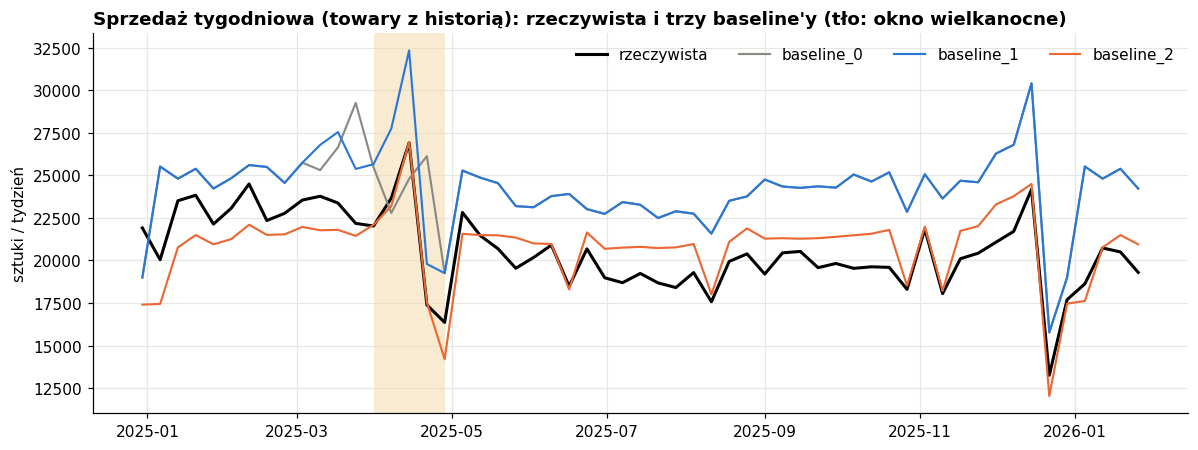

Zapisano: dane/eda/wynik_10_baseline_metryki.csv (24 wierszy)
Zapisano: dane/interim/baseline_eda_tydzien.parquet (446477, 6)


In [10]:
import matplotlib.pyplot as plt
osx = tygodnie[idx_test]
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(osx, A_t[ma_hist].sum(axis=0), color="black", lw=2, label="rzeczywista")
for kol_, (k, f) in zip([ew.SZARY, ew.NIEB, ew.POM], {k: Fz[k] for k in PROGNOZY}.items()):
    ax.plot(osx, f[ma_hist].sum(axis=0), color=kol_, lw=1.4, label=k)
for t in osx[t_wlk]:
    ax.axvspan(t, t + pd.Timedelta(days=7), color="#f3d9a4", alpha=0.5, lw=0)
ax.set_title("Sprzedaż tygodniowa (towary z historią): rzeczywista i trzy baseline'y (tło: okno wielkanocne)")
ax.set_ylabel("sztuki / tydzień"); ax.legend(ncol=4, frameon=False)
plt.tight_layout(); plt.show()

tab_wyn = pd.concat([tab.reset_index().rename(columns={"index": "wariant"}).assign(typ="wszystkie z historią", towary=int(ma_hist.sum())),
                     tab_typ], ignore_index=True)
ew.zapisz_wynik(tab_wyn, "wynik_10_baseline_metryki.csv", index=False)
os.makedirs("dane/interim", exist_ok=True)
dl = pd.DataFrame({"SKU": np.repeat(SKU, len(idx_test)), "Tydzien": np.tile(tygodnie[idx_test].values, len(SKU)),
                   "Rzeczywiste": A_t.ravel(), **{k: v.ravel() for k, v in PROGNOZY.items()}})
dl = dl[(dl[["Rzeczywiste", *PROGNOZY]].fillna(0) != 0).any(axis=1)]
dl.to_parquet("dane/interim/baseline_eda_tydzien.parquet", compression="zstd", index=False)
print("Zapisano: dane/interim/baseline_eda_tydzien.parquet", dl.shape)